# Lab 5: Hierarchical and DBSCAN Clustering on the Wine Dataset

**Name:** Sowmya Cheruku  
**Course:** MSCS 634 – Advanced Big Data and Data Mining  
**University:** University of the Cumberlands  
**Instructor:** Satish Penmatsa  
**Lab Assignment:** Lab 5 – Clustering with Hierarchical and DBSCAN Algorithms

## Introduction
In this lab I try two different clustering methods on the Wine dataset from scikit-learn: Agglomerative (Hierarchical) Clustering and DBSCAN. The Wine data has 178 wines from three different grape cultivars, described by 13 chemical measurements. Clustering is unsupervised, so the algorithms never see the cultivar labels. I still keep the true labels on the side so I can use Homogeneity and Completeness to check how well the clusters line up with the real cultivars.

## Step 1: Data Preparation and Exploration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, homogeneity_score, completeness_score
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_style("whitegrid")

In [2]:
wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)
y_true = wine.target   # only used for evaluation, never for fitting
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
dtypes: float64(13)
m

In [4]:
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [5]:
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Class counts (true cultivars):", dict(zip(*np.unique(y_true, return_counts=True))))

Shape: (178, 13)
Missing values: 0
Class counts (true cultivars): {np.int64(0): np.int64(59), np.int64(1): np.int64(71), np.int64(2): np.int64(48)}


**What I noticed:** There are 178 rows and 13 numeric features, with no missing values. The features are on very different scales. For example, `proline` is in the hundreds to over a thousand, while `hue` is around 1. Both algorithms use distances, so proline would dominate if I left the data as is. I standardize everything (mean 0, std 1) below.

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)
pd.DataFrame(X_scaled, columns=df.columns).describe().loc[["mean", "std"]].round(2)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
mean,-0.0,-0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0,-0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


The means are now about 0 and the standard deviations about 1.

Since the data has 13 dimensions, I can't plot it directly. I use PCA to squeeze it to 2 components **only for visualization**. All the clustering is done on the full 13 standardized features.

Variance explained by PC1 and PC2: [0.362 0.192] | total: 0.554


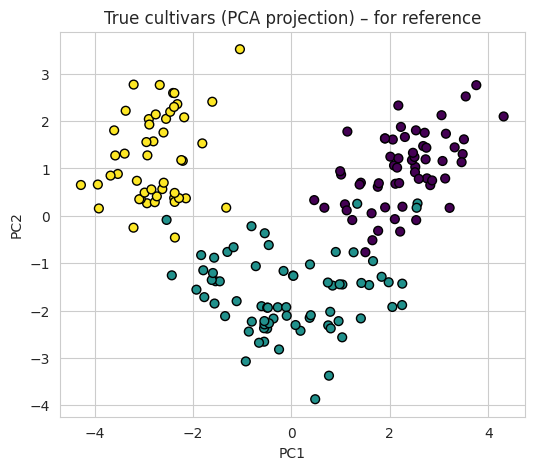

In [7]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print("Variance explained by PC1 and PC2:", pca.explained_variance_ratio_.round(3),
      "| total:", pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(6, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_true, cmap="viridis", s=40, edgecolor="k")
plt.title("True cultivars (PCA projection) – for reference")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.show()

This is what the "answer" looks like in 2D. The three cultivars form three fairly separate groups, which suggests clustering should work reasonably well, at least for a method that likes round, compact groups.

## Step 2: Hierarchical Clustering

I use Agglomerative Clustering with Ward linkage first, since Ward tries to keep clusters compact and usually works well on standardized numeric data. I try `n_clusters` = 2, 3, 4, and 5.

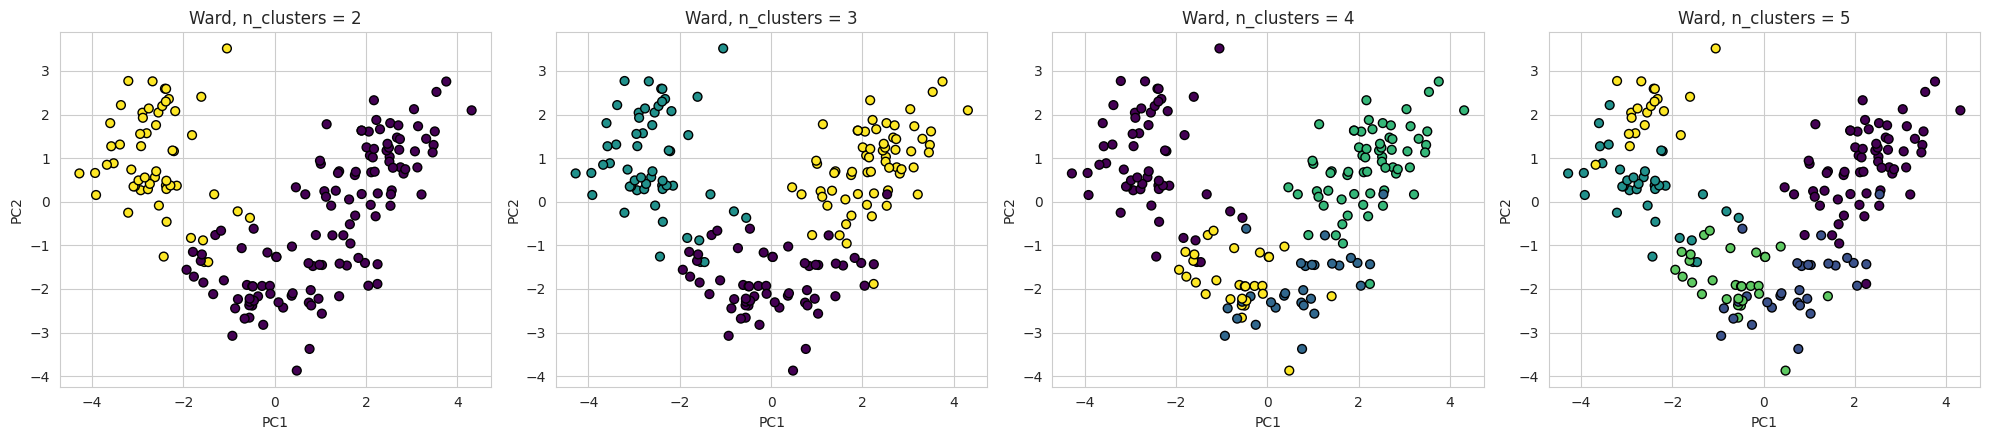

,n_clusters,Silhouette,Homogeneity,Completeness
0,2,0.267,0.444,0.774
1,3,0.277,0.790,0.783
2,4,0.226,0.790,0.649
3,5,0.187,0.811,0.576


In [8]:
rows = []
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, k in zip(axes, [2, 3, 4, 5]):
    labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_scaled)
    ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap="viridis", s=40, edgecolor="k")
    ax.set_title(f"Ward, n_clusters = {k}")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    rows.append({"n_clusters": k,
                 "Silhouette": silhouette_score(X_scaled, labels),
                 "Homogeneity": homogeneity_score(y_true, labels),
                 "Completeness": completeness_score(y_true, labels)})
plt.tight_layout(); plt.show()
hier_results = pd.DataFrame(rows).round(3)
hier_results

**Interpretation:** With `n_clusters = 3` Homogeneity (0.790) and Completeness (0.783) are both high and almost equal, which means the clusters are mostly pure and each cultivar mostly stays in one cluster. Going to 2 clusters merges cultivars, so Homogeneity drops to 0.444. Going to 4 or 5 splits a cultivar, so Completeness drops. Silhouette is highest at k = 3 (0.277). This matches the three real cultivars. Silhouette scores are low overall because the wine classes overlap a bit in 13-D space.

I also tried other linkage methods with k = 3 to see if Ward was a good choice.

In [9]:
rows = []
for link in ["ward", "complete", "average", "single"]:
    labels = AgglomerativeClustering(n_clusters=3, linkage=link).fit_predict(X_scaled)
    rows.append({"linkage": link,
                 "Silhouette": silhouette_score(X_scaled, labels),
                 "Homogeneity": homogeneity_score(y_true, labels),
                 "Completeness": completeness_score(y_true, labels),
                 "Cluster sizes": np.bincount(labels).tolist()})
pd.DataFrame(rows).round(3)

,linkage,Silhouette,Homogeneity,Completeness,Cluster sizes
0,ward,0.277,0.790,0.783,"[58, 56, 64]"
1,complete,0.204,0.616,0.613,"[69, 58, 51]"
2,average,0.158,0.010,0.093,"[174, 1, 3]"
3,single,0.183,0.019,0.175,"[174, 3, 1]"


Ward is clearly the best here. Average and single linkage put almost every point in one giant cluster and the other clusters have only one or two points (see "Cluster sizes"), so their Homogeneity is near 0. This is the "chaining effect": those methods link points through nearest neighbours and a few outliers end up as their own clusters. Ward's preference for balanced, compact clusters fits this dataset much better.

### Dendrogram

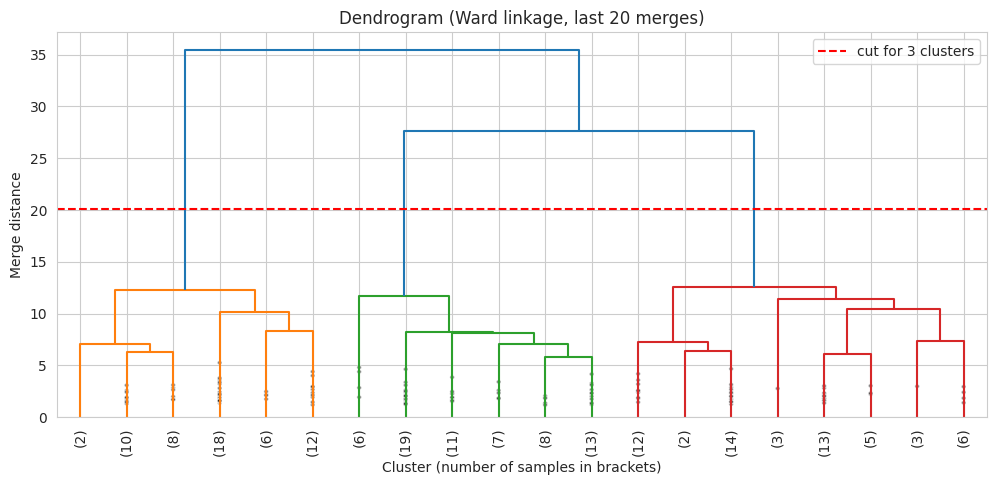

In [10]:
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=20, leaf_rotation=90, leaf_font_size=10,
           show_contracted=True)
plt.title("Dendrogram (Ward linkage, last 20 merges)")
plt.xlabel("Cluster (number of samples in brackets)")
plt.ylabel("Merge distance")
# horizontal cut that gives 3 clusters
cut = (Z[-3, 2] + Z[-2, 2]) / 2
plt.axhline(y=cut, color="red", linestyle="--", label="cut for 3 clusters")
plt.legend()
plt.show()

**Reading the dendrogram:** The y-axis is the distance at which two clusters get merged. The last two merges (at the top) happen at much larger distances than the earlier ones, with a big jump between the 3-cluster and 2-cluster levels. Drawing a horizontal line just below that jump (the red dashed line) cuts the tree into **3 clusters**, which agrees with the true number of cultivars and with the best metrics I got above. If I cut lower I would get more, smaller clusters, and if I cut higher I would be forcing different groups together.

## Step 3: DBSCAN Clustering

DBSCAN needs two parameters: `eps` (neighbourhood radius) and `min_samples` (points needed to be a core point). To get a sensible range for `eps` I plot a k-distance graph: for each point I find the distance to its k-th nearest neighbour, sort them, and look for the "elbow".

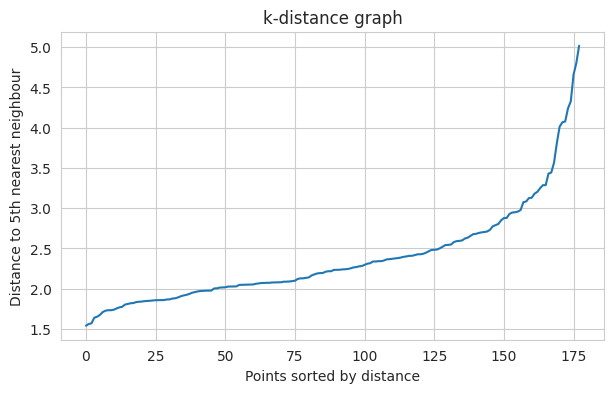

Median k-distance: 2.23 | 90th percentile: 3.13


In [11]:
k = 5
nn = NearestNeighbors(n_neighbors=k).fit(X_scaled)
dist, _ = nn.kneighbors(X_scaled)
kdist = np.sort(dist[:, -1])

plt.figure(figsize=(7, 4))
plt.plot(kdist)
plt.xlabel("Points sorted by distance"); plt.ylabel(f"Distance to {k}th nearest neighbour")
plt.title("k-distance graph")
plt.show()
print("Median k-distance:", kdist.round(2)[len(kdist)//2], "| 90th percentile:", np.percentile(kdist, 90).round(2))

There's no really sharp elbow, but the curve starts to rise faster at about 2 to 3. So I test `eps` from 1.5 to 4 and `min_samples` of 3, 5, and 10.

**A note on the metrics:** The Silhouette Score is calculated only on the non-noise points (and only if DBSCAN finds at least 2 clusters), because noise points aren't really in any cluster. For Homogeneity and Completeness I treat the noise label (-1) as its own group, which punishes DBSCAN for leaving many points unassigned.

In [12]:
rows = []
for eps in [1.5, 2.0, 2.5, 3.0, 3.5, 4.0]:
    for ms in [3, 5, 10]:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        mask = labels != -1
        n_clusters = len(set(labels[mask]))
        sil = silhouette_score(X_scaled[mask], labels[mask]) if n_clusters > 1 else np.nan
        rows.append({"eps": eps, "min_samples": ms, "clusters": n_clusters,
                     "noise points": int((~mask).sum()),
                     "Silhouette (non-noise)": sil,
                     "Homogeneity": homogeneity_score(y_true, labels),
                     "Completeness": completeness_score(y_true, labels)})
dbscan_results = pd.DataFrame(rows).round(3)
dbscan_results

,eps,min_samples,clusters,noise points,Silhouette (non-noise),Homogeneity,Completeness
0,1.5,3,8,147,0.331,0.189,0.251
1,1.5,5,0,178,NaN,0.000,1.000
2,1.5,10,0,178,NaN,0.000,1.000
3,2.0,3,5,64,0.211,0.442,0.372
4,2.0,5,5,85,0.240,0.362,0.325
5,2.0,10,1,139,NaN,0.289,0.596
6,2.5,3,1,23,NaN,0.067,0.189
7,2.5,5,1,24,NaN,0.058,0.158
8,2.5,10,2,32,0.323,0.504,0.560
9,3.0,3,2,7,0.239,0.031,0.135


**What the grid shows:**
- **Small eps (1.5)**: with `min_samples` of 5 or 10, *every* point is noise (0 clusters), because the neighbourhoods are too small to have enough neighbours. With `min_samples = 3` I get 8 small clusters but 147 of 178 points are noise.
- **Medium eps (2.0 to 2.5)**: this is the range where DBSCAN starts to find real structure. `eps = 2.5, min_samples = 10` gives 2 clusters with 32 noise points and the best combined scores of the grid (Silhouette 0.323, Homogeneity 0.504, Completeness 0.560).
- **Large eps (3.0 and up)**: the neighbourhoods become so big that nearly all points are linked into one cluster, so Homogeneity and Completeness fall to almost 0.
- **Higher min_samples** makes the algorithm stricter, which creates more noise at a given eps.

Next I plot a few settings and highlight noise in red.

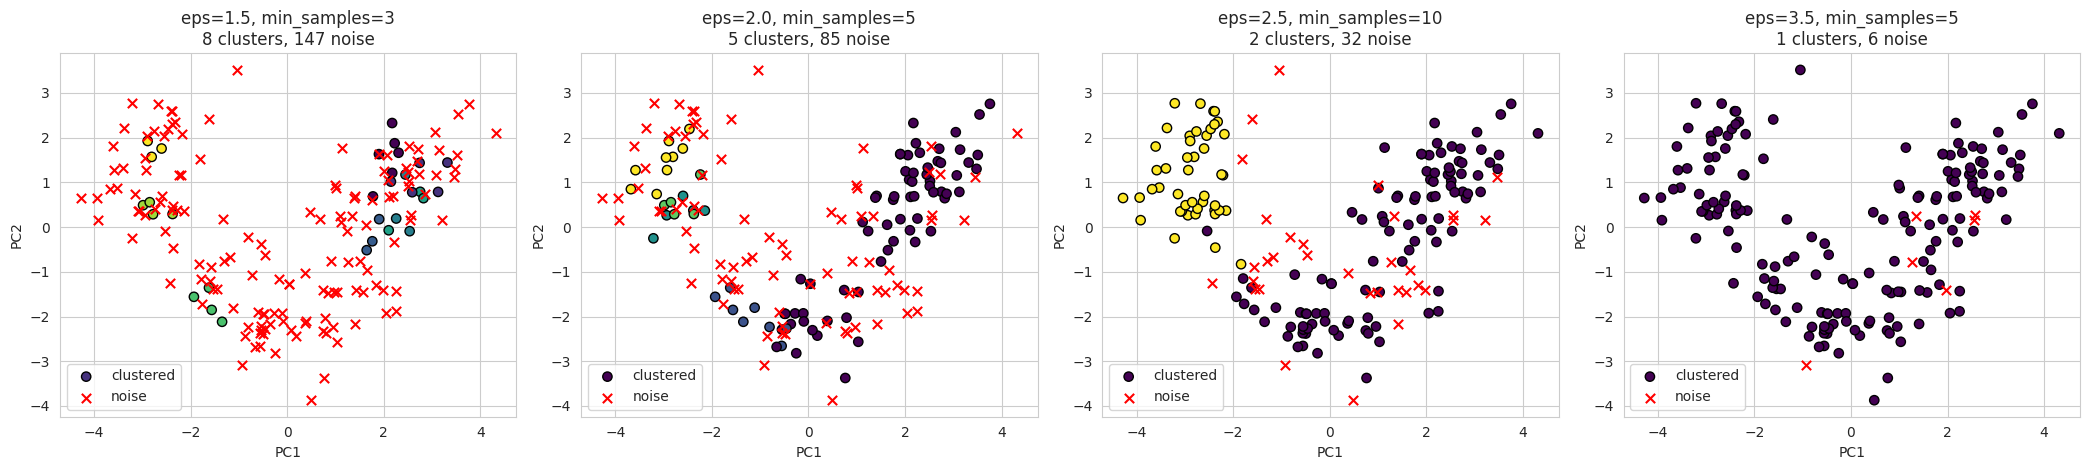

In [13]:
settings = [(1.5, 3), (2.0, 5), (2.5, 10), (3.5, 5)]
fig, axes = plt.subplots(1, 4, figsize=(21, 4.8))
for ax, (eps, ms) in zip(axes, settings):
    labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
    noise = labels == -1
    ax.scatter(X_pca[~noise, 0], X_pca[~noise, 1], c=labels[~noise], cmap="viridis",
               s=45, edgecolor="k", label="clustered")
    ax.scatter(X_pca[noise, 0], X_pca[noise, 1], c="red", marker="x", s=45, label="noise")
    ax.set_title(f"eps={eps}, min_samples={ms}\n{len(set(labels[~noise]))} clusters, {noise.sum()} noise")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(loc="best")
plt.tight_layout(); plt.show()

The plots match the table. At eps = 1.5 almost everything is red (noise). At eps = 3.5 there's essentially one big cluster. The middle settings (2.0 and 2.5) give a more balanced picture, but even there DBSCAN can't cleanly separate the three cultivars.

### Final DBSCAN model and comparison metrics

In [14]:
best_eps, best_ms = 2.5, 10
db_labels = DBSCAN(eps=best_eps, min_samples=best_ms).fit_predict(X_scaled)
mask = db_labels != -1

print(f"DBSCAN (eps={best_eps}, min_samples={best_ms})")
print("Clusters found:", len(set(db_labels[mask])), "| Noise points:", (~mask).sum())
print("Silhouette (non-noise):", round(silhouette_score(X_scaled[mask], db_labels[mask]), 3))
print("Homogeneity:", round(homogeneity_score(y_true, db_labels), 3))
print("Completeness:", round(completeness_score(y_true, db_labels), 3))

hier_labels = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X_scaled)
comparison = pd.DataFrame({
    "Hierarchical (Ward, k=3)": [silhouette_score(X_scaled, hier_labels),
                                 homogeneity_score(y_true, hier_labels),
                                 completeness_score(y_true, hier_labels), 0],
    f"DBSCAN (eps={best_eps}, min_samples={best_ms})": [silhouette_score(X_scaled[mask], db_labels[mask]),
                                 homogeneity_score(y_true, db_labels),
                                 completeness_score(y_true, db_labels), int((~mask).sum())]
}, index=["Silhouette", "Homogeneity", "Completeness", "Noise points"]).round(3)
comparison

DBSCAN (eps=2.5, min_samples=10)
Clusters found: 2 | Noise points: 32
Silhouette (non-noise): 0.323
Homogeneity: 0.504
Completeness: 0.56


,"Hierarchical (Ward, k=3)","DBSCAN (eps=2.5, min_samples=10)"
Silhouette,0.277,0.323
Homogeneity,0.790,0.504
Completeness,0.783,0.560
Noise points,0.000,32.000


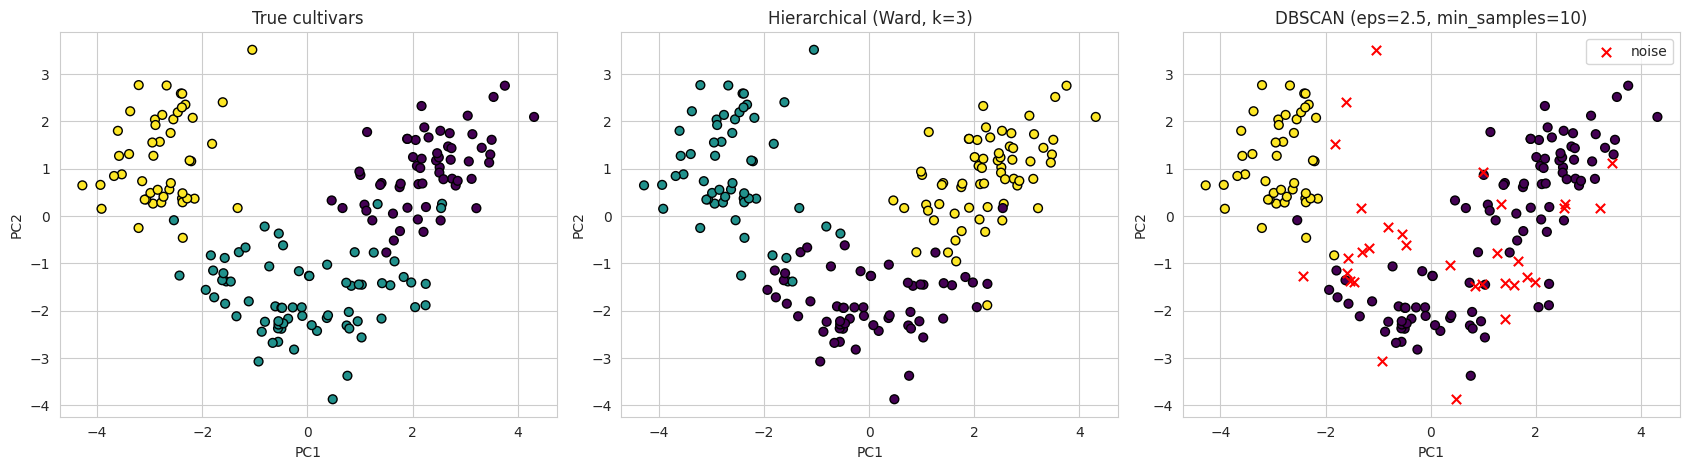

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y_true, cmap="viridis", s=40, edgecolor="k")
axes[0].set_title("True cultivars")
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=hier_labels, cmap="viridis", s=40, edgecolor="k")
axes[1].set_title("Hierarchical (Ward, k=3)")
axes[2].scatter(X_pca[mask, 0], X_pca[mask, 1], c=db_labels[mask], cmap="viridis", s=40, edgecolor="k")
axes[2].scatter(X_pca[~mask, 0], X_pca[~mask, 1], c="red", marker="x", s=45, label="noise")
axes[2].set_title(f"DBSCAN (eps={best_eps}, min_samples={best_ms})"); axes[2].legend()
for a in axes: a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()

## Step 4: Analysis and Insights

### Comparing Hierarchical and DBSCAN
Hierarchical clustering with Ward linkage and 3 clusters did much better on this dataset. It got a Homogeneity of 0.790 and Completeness of 0.783, versus 0.504 and 0.560 for my best DBSCAN setting. It also assigns every wine to a cluster, while DBSCAN left 32 of the 178 wines (about 18%) as noise and only found 2 clusters. The Silhouette Scores are similar (0.277 for hierarchical and 0.323 for DBSCAN), but the DBSCAN number is computed after removing the noise points, so it isn't a fair like-for-like comparison. A higher silhouette here mostly means DBSCAN kept only the easy, tightly packed points.

### How parameters influenced the results
- **Hierarchical:** The two choices that mattered were the linkage method and `n_clusters`. Ward gave good, balanced clusters while single and average linkage gave one giant cluster plus tiny ones. For `n_clusters`, 3 was best, and the dendrogram showed the same thing with a big jump in merge distance before the last 2 merges. Too few clusters (2) merged real cultivars (low Homogeneity) and too many (4 to 5) split them (lower Completeness).
- **DBSCAN:** Results were very sensitive to `eps`. Too small and everything is noise. Too large and everything is one cluster. Only a narrow band in the middle gave something useful, and it still didn't recover three groups. `min_samples` controlled how strict the algorithm was: higher values produced more noise points at the same eps.

### Strengths and weaknesses
**Hierarchical clustering**
- Strengths: no need to pick a number of clusters up front (the dendrogram helps choose it), results are deterministic, and the dendrogram is easy to interpret. Worked very well with Ward on standardized data.
- Weaknesses: you still need to choose a linkage and a cut level, results varied a lot by linkage, it is sensitive to outliers with single/average linkage, and it scales badly to large datasets (memory and time grow quickly with n).

**DBSCAN**
- Strengths: finds clusters of arbitrary shape, doesn't need `n_clusters`, and explicitly detects outliers as noise.
- Weaknesses: very sensitive to `eps` and `min_samples`, and a single global `eps` has trouble when clusters have different densities. In 13 dimensions distances become less meaningful (the "curse of dimensionality") and the wine classes are not separated by low-density gaps, so DBSCAN doesn't fit this data well.

### Conclusion
For the Wine dataset, Agglomerative Clustering with Ward linkage and 3 clusters was the better choice, mostly because the three cultivars form compact, roughly spherical groups in the standardized feature space. DBSCAN would likely be more useful on data with irregular shapes or clear noise. If I had more time I would try dimensionality reduction (e.g., clustering on the first few PCA components) before running DBSCAN, and compare with K-Means.